# BÀI THỰC HÀNH 04: CHUẨN HÓA DỮ LIỆU (DATA TRANSFORMATION)
- Mục tiêu: Khảo sát các phương án chuẩn hóa và thiết kế Pipeline chống rò rỉ dữ liệu.

In [1]:
from pathlib import Path
import sys,hashlib
import pandas as pd
import numpy as np
from IPython.display import display
assert sys.version_info[:2] == (3,14)
ROOT = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'dataLabanAI.xlsx').is_file())
workbook_path = ROOT/'dataLabanAI.xlsx'
sha_before = hashlib.sha256(workbook_path.read_bytes()).hexdigest()
sha_notebook00 = 'c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8'
assert sha_before == sha_notebook00, 'Workbook khác phiên bản Notebook 00; cần audit lại trước xử lý.'
excel = pd.ExcelFile(workbook_path)
assert excel.sheet_names == ['THONG_TIN','RIASEC_27','SO_THICH_6','CODEBOOK_33','KIEM_TRA']
raw_riasec = pd.read_excel(excel,sheet_name='RIASEC_27')
raw_q5 = pd.read_excel(excel,sheet_name='SO_THICH_6')
raw_codebook = pd.read_excel(excel,sheet_name='CODEBOOK_33')
# Bản sao gốc dùng đối chiếu, không thay đổi các DataFrame này.
original_riasec = raw_riasec.copy(deep=True)
original_q5 = raw_q5.copy(deep=True)
original_codebook = raw_codebook.copy(deep=True)
print('Python:',sys.version,'; Interpreter:',sys.executable)
print('SHA-256:',sha_before)
display(pd.DataFrame([{'Sheet':name,'Số dòng':len(frame),'Số cột':frame.shape[1]}
    for name,frame in [('RIASEC_27',raw_riasec),('SO_THICH_6',raw_q5),('CODEBOOK_33',raw_codebook)]]))


Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)] ; Interpreter: C:\Users\DELL\AppData\Local\Programs\Python\Python314\python.exe
SHA-256: c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8
         Sheet  Số dòng  Số cột
0    RIASEC_27     4910      28
1   SO_THICH_6     4910       7
2  CODEBOOK_33       33       5


In [2]:
question_columns = ['R1','I1','A1','R2','I2','A2','S1','S2','R3','A3','S3','E1','R4','S4','E2','R5','I3','A4','E3','I4','A5','E4','C1','E5','C2','C3','C4']
q5_columns = ['Q5_LikeRe','Q5_LikeIn','Q5_LikeAr','Q5_LikeSo','Q5_LikeEn','Q5_LikeCo']
survey_columns = question_columns+q5_columns
assert raw_riasec.shape == (4910,28) and raw_q5.shape == (4910,7)
assert list(raw_riasec.columns) == ['SOURCE_ROW']+question_columns
assert list(raw_q5.columns) == ['SOURCE_ROW']+q5_columns
assert raw_codebook.MA_COT.is_unique and raw_codebook.MA_COT.tolist() == survey_columns
assert raw_codebook.iloc[:27]['LOAI'].eq('RIASEC rút gọn').all()
assert raw_codebook.iloc[27:]['LOAI'].eq('Mức ưa thích nhóm nghề').all()
assert raw_codebook.iloc[:27]['THANG_DIEM_GOC'].nunique()==1
assert raw_codebook.iloc[27:]['THANG_DIEM_GOC'].nunique()==1
for frame in [raw_riasec,raw_q5]:
    assert frame.SOURCE_ROW.notna().all() and frame.SOURCE_ROW.is_unique
    assert pd.api.types.is_integer_dtype(frame.SOURCE_ROW)
assert set(raw_riasec.SOURCE_ROW) == set(raw_q5.SOURCE_ROW)
merged = raw_riasec.merge(raw_q5,on='SOURCE_ROW',how='outer',validate='one_to_one',indicator=True,sort=False)
display(merged['_merge'].value_counts().rename('Số dòng sau ghép').to_frame())
assert len(merged) == len(raw_riasec) == len(raw_q5) == 4910
assert merged['_merge'].eq('both').all()
merged = merged.drop(columns='_merge').set_index('SOURCE_ROW').loc[raw_riasec.SOURCE_ROW].reset_index()
assert merged.SOURCE_ROW.equals(raw_riasec.SOURCE_ROW)
assert merged[question_columns].equals(raw_riasec[question_columns])
assert merged[q5_columns].equals(raw_q5.set_index('SOURCE_ROW').loc[raw_riasec.SOURCE_ROW,q5_columns].reset_index(drop=True))
df_original = merged.copy(deep=True)
raw_survey = df_original[survey_columns].copy()
print('PASS: ghép một-một, không mất/thêm dòng, giữ thứ tự nguồn và 33 biến.')


PASS: ghép một-một, không mất/thêm dòng, giữ thứ tự nguồn và 33 biến.


            Số dòng sau ghép
_merge                      
both                    4910
left_only                  0
right_only                 0

In [3]:
type_rows = []
for col in survey_columns:
    values = raw_survey[col]
    numeric = pd.to_numeric(values,errors='coerce')
    is_numeric_cell = values.map(lambda value:isinstance(value,(int,float,np.integer,np.floating)) and not isinstance(value,(bool,np.bool_)))
    valid = is_numeric_cell & numeric.isin([1,2,3,4,5])
    type_rows.append({'Cột':col,'dtype gốc':str(values.dtype),'Thiếu':int(values.isna().sum()),
        'Sai kiểu hoặc ngoài miền':int((values.notna() & ~valid).sum())})
type_check = pd.DataFrame(type_rows).set_index('Cột')
display(type_check)
if type_check['Thiếu'].sum() or type_check['Sai kiểu hoặc ngoài miền'].sum():
    raise RuntimeError('Có giá trị sai/thiếu; dừng để quyết định xử lý, không tự sửa.')
survey_int = raw_survey.astype('int64')
assert np.array_equal(survey_int.to_numpy(),raw_survey.to_numpy())
assert survey_int.isin(range(1,6)).all().all()
assert all(pd.api.types.is_integer_dtype(dtype) for dtype in survey_int.dtypes)
answers27 = survey_int[question_columns].copy()
preferences6 = survey_int[q5_columns].copy()
print('PASS: đủ 33 biến, không thiếu/sai kiểu/ngoài miền; chuyển int64 không đổi giá trị.')


PASS: đủ 33 biến, không thiếu/sai kiểu/ngoài miền; chuyển int64 không đổi giá trị.


          dtype gốc  Thiếu  Sai kiểu hoặc ngoài miền
Cột                                                 
R1            int64      0                         0
I1            int64      0                         0
A1            int64      0                         0
R2            int64      0                         0
I2            int64      0                         0
A2            int64      0                         0
S1            int64      0                         0
S2            int64      0                         0
R3            int64      0                         0
A3            int64      0                         0
S3            int64      0                         0
E1            int64      0                         0
R4            int64      0                         0
S4            int64      0                         0
E2            int64      0                         0
R5            int64      0                         0
I3            int64      0                    

In [4]:
from sklearn.model_selection import GroupShuffleSplit
import sklearn
X = answers27.copy()
y = preferences6.copy()
groups = pd.Series(pd.factorize(pd.MultiIndex.from_frame(X),sort=False)[0],index=X.index,name='group_X27')
splitter = GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
train_pos,test_pos = next(splitter.split(X,groups=groups))
X_train,X_test = X.iloc[train_pos].copy(),X.iloc[test_pos].copy()
y_train,y_test = y.iloc[train_pos].copy(),y.iloc[test_pos].copy()
groups_train,groups_test = groups.iloc[train_pos].copy(),groups.iloc[test_pos].copy()
assert X_train.shape==(3963,27) and X_test.shape==(947,27)
assert y_train.shape==(3963,6) and y_test.shape==(947,6)
assert groups_train.nunique()==3568 and groups_test.nunique()==892
assert X.index.is_unique and X_train.index.intersection(X_test.index).empty
assert len(X_train)+len(X_test)==4910
assert set(X_train.index)|set(X_test.index)==set(X.index)
assert set(groups_train).isdisjoint(groups_test)
assert set(X_train.itertuples(index=False,name=None)).isdisjoint(X_test.itertuples(index=False,name=None))
assert list(X_train.columns)==list(X_test.columns)==question_columns
assert list(y_train.columns)==list(y_test.columns)==q5_columns
assert y_train.index.equals(X_train.index) and y_test.index.equals(X_test.index)
assert y_train.equals(y.loc[X_train.index]) and y_test.equals(y.loc[X_test.index])
train_index_sha256=hashlib.sha256(np.asarray(X_train.index,dtype='<i8').tobytes()).hexdigest()
test_index_sha256=hashlib.sha256(np.asarray(X_test.index,dtype='<i8').tobytes()).hexdigest()
assert train_index_sha256=='471fecbbc5d665e949eae03bcdebedc996044f30136a56d8b1d698ad3d7e2d4d'
assert test_index_sha256=='92594157a2b76a9d59f375dd14bf6617cd5b58232f368b86688e17c011d8392b'
print('PASS: đúng index Notebook 02; Train 3963×27, 3568 group; Test 947×27, 892 group; y có 6 cột.')
print('SHA index Train/Test:',train_index_sha256,test_index_sha256)
print('pandas/numpy/sklearn:',pd.__version__,np.__version__,sklearn.__version__)
# Giữ codebook và đường dẫn/hash; bỏ các DataFrame có phản hồi Test/toàn tập.
del X_test,y_test,groups_test,X,y,groups,train_pos,test_pos
# Các bản sao toàn tập từ bước đọc/làm sạch cũng không dùng cho minh họa chuẩn hóa.
del raw_riasec,raw_q5,original_riasec,original_q5,merged,df_original,raw_survey,survey_int,answers27,preferences6

# Bỏ cả alias còn lại của các vòng kiểm tra kiểu/khóa.
del frame,values,numeric,is_numeric_cell,valid


PASS: đúng index Notebook 02; Train 3963×27, 3568 group; Test 947×27, 892 group; y có 6 cột.
SHA index Train/Test: 471fecbbc5d665e949eae03bcdebedc996044f30136a56d8b1d698ad3d7e2d4d 92594157a2b76a9d59f375dd14bf6617cd5b58232f368b86688e17c011d8392b
pandas/numpy/sklearn: 3.0.6 2.5.3 1.9.1


## Bước 1: So sánh các phương pháp chuẩn hóa dữ liệu
- Phương án: Giữ nguyên Likert (Raw), Chuẩn hóa Min-Max, Chuẩn hóa Z-score (StandardScaler).

In [5]:
from sklearn.preprocessing import StandardScaler,MinMaxScaler
X_train_snapshot=X_train.copy(deep=True)
y_train_snapshot=y_train.copy(deep=True)
X_train_raw=X_train.copy(deep=True)
assert X_train_raw.shape==(3963,27)
assert list(X_train_raw.columns)==question_columns
assert not set(q5_columns+['SOURCE_ROW']).intersection(X_train_raw.columns)
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in X_train_raw.dtypes)
assert X_train_raw.isin(range(1,6)).all().all()
assert np.isfinite(X_train_raw.to_numpy(dtype=float)).all()
raw_stats=pd.DataFrame({'min':X_train_raw.min(),'max':X_train_raw.max(),
    'mean':X_train_raw.mean(),'SD (ddof=0)':X_train_raw.std(ddof=0),
    'variance (ddof=0)':X_train_raw.var(ddof=0)})
constant_columns=raw_stats.index[raw_stats['variance (ddof=0)'].eq(0)].tolist()
display(raw_stats.round(6))
print('Cột hằng:',constant_columns)
assert not constant_columns, 'Có cột hằng: báo cáo, không tự loại hoặc thay câu.'
print('Shape Raw:',X_train_raw.shape,'; số cột có min=1/max=5:',int(raw_stats['min'].eq(1).sum()),int(raw_stats['max'].eq(5).sum()))


Cột hằng: []
Shape Raw: (3963, 27) ; số cột có min=1/max=5: 27 27


    min  max      mean  SD (ddof=0)  variance (ddof=0)
R1    1    5  2.552864     1.108050           1.227776
I1    1    5  2.680545     1.114397           1.241880
A1    1    5  2.806712     1.129507           1.275786
R2    1    5  2.636387     1.065012           1.134250
I2    1    5  2.600050     1.085667           1.178673
A2    1    5  2.589200     1.087773           1.183249
S1    1    5  2.724956     1.135330           1.288973
S2    1    5  2.787282     1.120281           1.255029
R3    1    5  2.490537     1.104940           1.220892
A3    1    5  2.984355     1.220879           1.490545
S3    1    5  2.657583     1.133788           1.285476
E1    1    5  2.642443     1.118326           1.250654
R4    1    5  2.479182     1.041291           1.084288
S4    1    5  3.181681     1.150891           1.324550
E2    1    5  2.946253     1.169849           1.368547
R5    1    5  2.294474     1.024473           1.049546
I3    1    5  2.734797     1.169280           1.367215
A4    1   

In [6]:
standard_scaler_demo=StandardScaler()
standard_scaler_demo.fit(X_train_raw)
X_train_standard_demo=pd.DataFrame(standard_scaler_demo.transform(X_train_raw),
    index=X_train_raw.index,columns=X_train_raw.columns)
assert X_train_standard_demo.shape==X_train_raw.shape
assert np.isfinite(X_train_standard_demo.to_numpy()).all()
assert standard_scaler_demo.n_samples_seen_==3963
assert standard_scaler_demo.n_features_in_==27
assert np.array_equal(standard_scaler_demo.feature_names_in_,X_train_raw.columns)
assert np.allclose(standard_scaler_demo.mean_,X_train_raw.mean())
assert np.allclose(standard_scaler_demo.var_,X_train_raw.var(ddof=0))
assert np.allclose(X_train_standard_demo.mean(),0,atol=1e-12)
assert np.allclose(X_train_standard_demo.std(ddof=0),1,atol=1e-12)
standard_stats=pd.DataFrame({'min':X_train_standard_demo.min(),'max':X_train_standard_demo.max(),
    'mean':X_train_standard_demo.mean(),'SD (ddof=0)':X_train_standard_demo.std(ddof=0)})
display(standard_stats.round(6))
print('Mean tuyệt đối lớn nhất:',X_train_standard_demo.mean().abs().max())
print('Sai lệch SD so với 1 lớn nhất:',(X_train_standard_demo.std(ddof=0)-1).abs().max())


Mean tuyệt đối lớn nhất: 2.1515298584711588e-16
Sai lệch SD so với 1 lớn nhất: 3.3306690738754696e-16


         min       max  mean  SD (ddof=0)
R1 -1.401438  2.208506  -0.0          1.0
I1 -1.508031  2.081355  -0.0          1.0
A1 -1.599558  1.941810  -0.0          1.0
R2 -1.536496  2.219331   0.0          1.0
I2 -1.473795  2.210576  -0.0          1.0
A2 -1.460967  2.216272   0.0          1.0
S1 -1.519344  2.003862   0.0          1.0
S2 -1.595388  1.975146   0.0          1.0
R3 -1.348976  2.271130   0.0          1.0
A3 -1.625350  1.650979  -0.0          1.0
S3 -1.461986  2.066010  -0.0          1.0
E1 -1.468661  2.108112  -0.0          1.0
R4 -1.420527  2.420857  -0.0          1.0
S4 -1.895645  1.579924   0.0          1.0
E2 -1.663678  1.755566  -0.0          1.0
R5 -1.263551  2.640895  -0.0          1.0
I3 -1.483646  1.937264  -0.0          1.0
A4 -1.391726  2.012848  -0.0          1.0
E3 -1.701975  1.750764   0.0          1.0
I4 -1.545031  1.953302  -0.0          1.0
A5 -1.367411  2.301545  -0.0          1.0
E4 -1.523113  2.241800   0.0          1.0
C1 -1.545754  2.111454  -0.0      

In [7]:
minmax_scaler_demo=MinMaxScaler(feature_range=(0,1))
minmax_scaler_demo.fit(X_train_raw)
X_train_minmax_demo=pd.DataFrame(minmax_scaler_demo.transform(X_train_raw),
    index=X_train_raw.index,columns=X_train_raw.columns)
assert X_train_minmax_demo.shape==X_train_raw.shape
assert np.isfinite(X_train_minmax_demo.to_numpy()).all()
assert minmax_scaler_demo.n_samples_seen_==3963
assert minmax_scaler_demo.n_features_in_==27
assert np.array_equal(minmax_scaler_demo.feature_names_in_,X_train_raw.columns)
assert np.allclose(minmax_scaler_demo.data_min_,X_train_raw.min())
assert np.allclose(minmax_scaler_demo.data_max_,X_train_raw.max())
assert np.all(minmax_scaler_demo.data_range_>0)
assert X_train_minmax_demo.ge(-1e-12).all().all()
assert X_train_minmax_demo.le(1+1e-12).all().all()
assert X_train_minmax_demo.var(ddof=0).gt(0).all()
minmax_stats=pd.DataFrame({'min gốc':X_train_raw.min(),'max gốc':X_train_raw.max(),
    'min biến đổi':X_train_minmax_demo.min(),'max biến đổi':X_train_minmax_demo.max(),
    'mean':X_train_minmax_demo.mean(),'SD (ddof=0)':X_train_minmax_demo.std(ddof=0)})
display(minmax_stats.round(6))
print('Số cột thực tế có min≈0:',int(np.isclose(minmax_stats['min biến đổi'],0).sum()))
print('Số cột thực tế có max≈1:',int(np.isclose(minmax_stats['max biến đổi'],1).sum()))


Số cột thực tế có min≈0: 27
Số cột thực tế có max≈1: 27


    min gốc  max gốc  min biến đổi  max biến đổi      mean  SD (ddof=0)
R1        1        5           0.0           1.0  0.388216     0.277013
I1        1        5           0.0           1.0  0.420136     0.278599
A1        1        5           0.0           1.0  0.451678     0.282377
R2        1        5           0.0           1.0  0.409097     0.266253
I2        1        5           0.0           1.0  0.400013     0.271417
A2        1        5           0.0           1.0  0.397300     0.271943
S1        1        5           0.0           1.0  0.431239     0.283832
S2        1        5           0.0           1.0  0.446821     0.280070
R3        1        5           0.0           1.0  0.372634     0.276235
A3        1        5           0.0           1.0  0.496089     0.305220
S3        1        5           0.0           1.0  0.414396     0.283447
E1        1        5           0.0           1.0  0.410611     0.279582
R4        1        5           0.0           1.0  0.369796     0

In [8]:
comparison_rows=[]
for name,data in [('Raw Likert 1–5',X_train_raw),('StandardScaler',X_train_standard_demo),('MinMaxScaler',X_train_minmax_demo)]:
    comparison_rows.append({'Biểu diễn':name,'Shape':str(data.shape),
        'Min toàn bộ':data.min().min(),'Max toàn bộ':data.max().max(),
        'Mean cột nhỏ nhất':data.mean().min(),'Mean cột lớn nhất':data.mean().max(),
        'SD cột nhỏ nhất (ddof=0)':data.std(ddof=0).min(),
        'SD cột lớn nhất (ddof=0)':data.std(ddof=0).max()})
comparison=pd.DataFrame(comparison_rows).set_index('Biểu diễn')
display(comparison.round(6))


                     Shape  Min toàn bộ  Max toàn bộ  Mean cột nhỏ nhất  Mean cột lớn nhất  SD cột nhỏ nhất (ddof=0)  SD cột lớn nhất (ddof=0)
Biểu diễn                                                                                                                                     
Raw Likert 1–5  (3963, 27)     1.000000     5.000000           2.294474           3.181681                  1.014502                  1.220879
StandardScaler  (3963, 27)    -1.895645     2.640895          -0.000000           0.000000                  1.000000                  1.000000
MinMaxScaler    (3963, 27)     0.000000     1.000000           0.323618           0.545420                  0.253625                  0.305220

## Bước 2: Phân tích khoảng cách hình học giữa các biểu diễn
- Đo lường: Khoảng cách Euclidean và Cosine giữa các mẫu khảo sát.

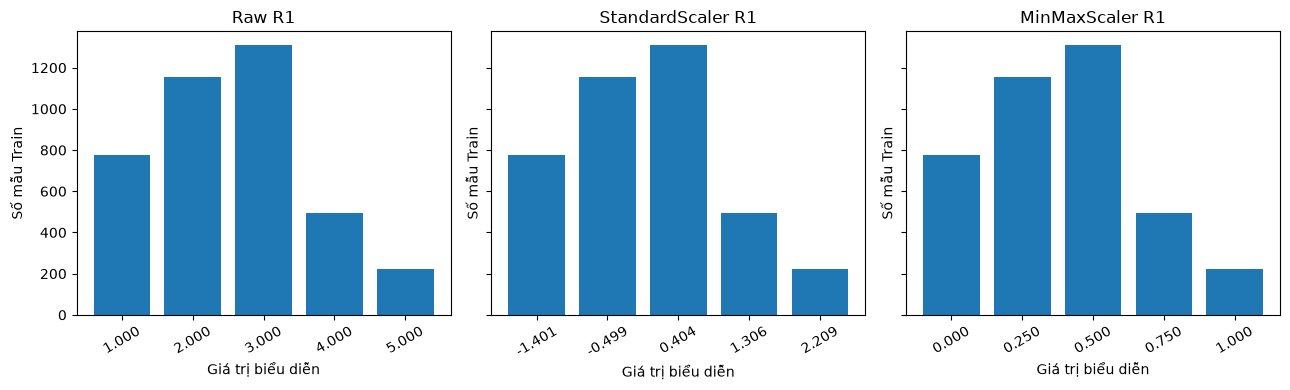

In [9]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,3,figsize=(13,4),sharey=True)
for ax,name,data in zip(axes,['Raw R1','StandardScaler R1','MinMaxScaler R1'],
                        [X_train_raw,X_train_standard_demo,X_train_minmax_demo]):
    counts=data['R1'].value_counts().sort_index()
    ax.bar(range(len(counts)),counts.to_numpy())
    ax.set_xticks(range(len(counts)),[f'{value:.3f}' for value in counts.index],rotation=30)
    ax.set(title=name,xlabel='Giá trị biểu diễn',ylabel='Số mẫu Train')
plt.tight_layout()
plt.show()

## Bước 3: Thiết kế Pipeline chuẩn hóa chống rò rỉ dữ liệu (Anti-Leakage)
- Chống rò rỉ: Scaler được đặt bên trong `Pipeline` để chỉ `fit` trên training fold nội bộ.

In [10]:
assert X_train.equals(X_train_snapshot) and X_train_raw.equals(X_train_snapshot)
assert y_train.equals(y_train_snapshot)
assert y_train.shape==(3963,6) and list(y_train.columns)==q5_columns
assert all(pd.api.types.is_integer_dtype(dtype) for dtype in y_train.dtypes)
assert y_train.isin(range(1,6)).all().all()
assert X_train.shape==(3963,27) and groups_train.nunique()==3568
for data in [X_train_raw,X_train_standard_demo,X_train_minmax_demo]:
    assert data.shape==(3963,27) and data.columns.equals(X_train.columns)
    assert data.index.equals(X_train.index)
    assert np.isfinite(data.to_numpy(dtype=float)).all()
assert hashlib.sha256(np.asarray(X_train.index,dtype='<i8').tobytes()).hexdigest()==train_index_sha256
assert 'X_test' not in globals() and 'y_test' not in globals()
assert 'raw_survey' not in globals() and 'survey_int' not in globals()
pd.testing.assert_frame_equal(raw_codebook,original_codebook)
sha_after=hashlib.sha256(workbook_path.read_bytes()).hexdigest()
assert sha_after==sha_before
print('PASS: X_train và sáu Q5 gốc không đổi; đúng 27 câu, index/group giữ nguyên.')
print('PASS: hai scaler chỉ fit/transform 3963 mẫu X_train; không transform Test hoặc y.')
print('SHA-256 workbook:',sha_after)


PASS: X_train và sáu Q5 gốc không đổi; đúng 27 câu, index/group giữ nguyên.
PASS: hai scaler chỉ fit/transform 3963 mẫu X_train; không transform Test hoặc y.
SHA-256 workbook: c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8


## Bước 4: Tổng kết và lựa chọn phương án chuẩn hóa
- Kết luận: Dùng StandardScaler cho Logistic Regression; Dùng Raw27 cho Random Forest và XGBoost.